# Song et al. 2022 — Prostate Cancer · 04 Expression
The unconditional expression step: place the EMT-driving transcription factors along the malignant pseudotime axis. The early/late TF pair is *derived from detectable expression* (fraction expressing > 3%), never assumed, and only TFs are shown (no effector genes such as VIM).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 4574 | pseudotime range 0.0 -> 9.77


### Derive the EMT-TF pair from detectable expression
Candidate panel spans the core EMT transcription-factor families (Snail, Zeb, Twist, Foxc, Prrx, plus Six1/Gsc) — wider than Snail/Zeb/Twist alone, **TFs only** (no effectors such as VIM, no lineage/AR-axis TFs). Each TF's fraction expressing, early/late means, and Spearman gradient vs pseudotime decide the early(root) → late(terminus) pair. Detection floor is adaptive: prefer >3% expressing, and when no EMT-TF clears it (as in a luminal AR-driven adenocarcinoma that retains epithelial identity) fall back to the most-detectable EMT-TFs (>1%), reporting the sparsity honestly — the same floor-fallback logic used for the sample threshold.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2','SIX1','GSC']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
# adaptive detection floor: prefer >3%, fall back to >1% (classical mesenchymal EMT-TFs are
# largely below detection in this luminal AR-driven adenocarcinoma)
FLOOR = 0.03
ok = df[df.frac_expr > FLOOR]
if len(ok) < 2:
    FLOOR = 0.01
    ok = df[df.frac_expr > FLOOR].sort_values('frac_expr', ascending=False).head(4)
    print(f'\nno EMT-TF clears 3% -> classical mesenchymal EMT program is below the usual detection floor;')
    print(f'falling back to the {len(ok)} most-detectable EMT-TFs (>1%):', ok['TF'].tolist())
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'detection floor used: >{FLOOR:.0%} expressing')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print(f'note: max EMT-TF detection is {df.frac_expr.max():.1%} -> EMT-TF activity is sparse; '
      f'panel is the honest low-EMT readout, not a strong program.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.024       0.012      0.009    -0.058    EARLY(root)
 SNAI2      0.014       0.008      0.008    -0.046 LATE(terminus)
  ZEB1      0.012       0.011      0.010    -0.031    EARLY(root)
  ZEB2      0.021       0.016      0.017    -0.026 LATE(terminus)
  SIX1      0.138       0.066      0.069    -0.026 LATE(terminus)
   GSC      0.005       0.003      0.001    -0.015    EARLY(root)
 PRRX1      0.005       0.003      0.004    -0.014 LATE(terminus)
 SNAI1      0.009       0.004      0.004    -0.008 LATE(terminus)
TWIST1      0.021       0.006      0.008     0.012 LATE(terminus)

no EMT-TF clears 3% -> classical mesenchymal EMT program is below the usual detection floor;
falling back to the 4 most-detectable EMT-TFs (>1%): ['SIX1', 'FOXC1', 'TWIST1', 'ZEB2']
detection floor used: >1% expressing
derived pair: FOXC1 (early/root) <-> TWIST1 (late/terminus)
note: max EMT-TF detection is 13.8% -> EMT-TF activity is sp

### EMT-TF overlay (`expression.pdf`)
Cells above the upper-quartile-among-expressers threshold for each TF are overlaid (categorical) on the grey manifold in the house orientation — the derived early TF in blue, late TF in red.

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.686, 'TWIST1': 0.676} | cells shown: {'FOXC1': 27, 'TWIST1': 25}
FOXC1: 2.4% expressing; 27 shown (upper quartile), mean pseudotime of shown cells = 0.54 (all cells = 0.44)
TWIST1: 2.1% expressing; 25 shown (upper quartile), mean pseudotime of shown cells = 0.46 (all cells = 0.44)
shown-cell pseudotime separation (FOXC1 vs TWIST1) = 0.09
saved expression.pdf


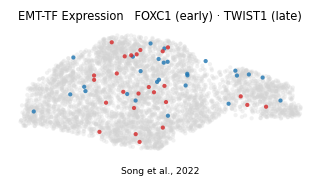

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Song et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')